# 學生學習與作業版｜任務 8：分析報告與可重現性

**姓名：**＿戴羽玄＿　**學號／組別：**＿C114118105＿　**完成日期：**＿2026/11/21＿

**學習目標：** 整理資料分析證據、記錄環境，建立可重跑的第一階段報告。

本單元與教師版「任務 8」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「延伸：主張如何連結證據」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 8.1 問題、證據、限制
報告必須對應資料與圖表，而非只有結論。對每個發現寫明使用欄位、有效筆數、處理方式及限制。


In [2]:
# 重現兩項可核對的證據：品質與平均成績
print("形狀：", df.shape)
print("欄位缺失：\n", df.isna().sum())
print("平均成績：", df["quiz_score"].mean())
print("睡眠與成績有效配對：", len(df.dropna(subset=["sleep_hours", "quiz_score"])))


形狀： (60, 7)
欄位缺失：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64
平均成績： 78.8
睡眠與成績有效配對： 58


## 📝 學生作業 08-Q1｜AI 查詢與作答：可重現性
**任務：**固定亂數種子是否足夠讓任何人在任何環境都得到完全相同結果？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini。我是 Python 與資料分析初學者。請說明種子、資料版本、套件版本、路徑與執行順序對 Notebook 重現性的影響。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：固定種子僅控制亂數生成序列，不足以保證跨環境完全重現。若儲存格執行順序或重複次數不同，會改變亂數狀態；不同套件版本的底層實作可能產生差異；原始資料版本更動會改變輸入源；而寫死本機檔案路徑則會讓其他人的環境無法順利讀取檔案。
- 我的理解與具體例子：固定亂數種子就像大家拿同一本密碼本，但如果翻頁順序不對或版本印錯，對出來的結果還是不一樣。例如：在Colab設定rng=np.random.default_rng(42) 後，若按順序執行抽樣儲存格會得到固定數列，但若不小心重複執行該抽樣儲存格一次，亂數狀態就會往下跳，導致後續產生的模擬資料與別人完全不同。若程式直接寫死自己電腦的C:\路徑，別人拿到檔案也會因為找不到路徑而無法執行。
- 查證來源／方式及日期（無法查證請註明）：NumPy官方文件 Random Generator https://numpy.org/doc/stable/reference/random/generator.html 。2026/11/21
- 我檢查或修正 AI 回答的地方：AI提供了固定種子後重複執行抽樣儲存格的驗證範例，我實際在Colab執行測試，確認不重設種子直接重跑抽樣格時，輸出的亂數確實會改變，並將說明重點緊扣題目為何僅固定亂數種子仍不足夠進行整理。


## 8.2 紀錄套件與環境
固定種子有助重現，但不同套件版本或計算環境仍可能有差異。記錄資料檔與取得方式，使用相對路徑，不暴露個人電腦路徑。


In [3]:
# 顯示環境資訊，不自動安裝或修改任何套件
import sys
import sklearn
import matplotlib
print("Python：", sys.version.split()[0])
print("numpy：", np.__version__, "pandas：", pd.__version__)
print("matplotlib：", matplotlib.__version__, "scikit-learn：", sklearn.__version__)


Python： 3.14.6
numpy： 2.4.6 pandas： 3.0.3
matplotlib： 3.11.0 scikit-learn： 1.9.0


## 📝 學生作業 08-Q2｜AI 查詢與作答：證據與主張
**任務：**一段分析報告如何讓讀者找到支持結論的數字及限制？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 08-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini。我是 Python 與資料分析初學者。請提供資料分析主張、對應表圖、有效筆數、限制的寫作架構，不要虛構我的結果。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：一份可信的分析報告應包含四個要素：第一是明確主張，只描述觀察到的趨勢或差異；第二是數據與表圖對應，附上實際統計值與圖表標題；第三是有效筆數與處理方式，交代扣除缺失值或極端值後的實際樣本數；第四是分析限制，說明資料生成背景並避免將相關誤判為因果。
- 我的理解與具體例子：寫分析報告就像寫實驗紀錄，不能只說我覺得有關，要把算式跟條件攤開讓別人檢查。例如：若要報告本資料集的螢幕時間與成績關係，不能只寫滑手機越久考越差，而應寫：「在排除1筆超過10小時的極端紀錄後，螢幕時間與測驗成績呈現中度負相關，但因資料由模擬公式生成且極端值在計分後才修改，此結果僅反映資料處理敏感度，不能推論真實因果。
- 查證來源／方式及日期（無法查證請註明）：Pandas官方文件 pandas.DataFrame.count https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html 。2026/11/21
- 我檢查或修正 AI 回答的地方：AI提供了通用的四段式報告架構模板，我將模板套用到實際執行輸出中，親自執行程式確認數字完全吻合，確保報告內容都有實際輸出作為依據。


## 8.3 第一階段報告框架
1. 問題、模擬資料來源與欄位。
2. 缺失、異常、重複的實際結果與處理理由。
3. 至少兩張圖、分組與變數關係。
4. 處理方案比較及限制。
5. AI 提示詞、人工修改、錯誤及驗證。
6. 重啟環境由上到下執行，檢查數字與報告一致。

**注意：**本階段已看過全體 60 筆，後續切出的測試資料不屬於完全未接觸過的新資料。


## 範例：主張如何連結證據
不要只寫「睡眠越多成績越高」。較好的描述是：先寫資料與有效樣本數，再呈現實際相關係數與圖表，最後揭露生成公式與因果限制。

**請學生核對：**輸出中的數字是否與報告文字一致？如不同應以重跑結果為準，不能要求 AI 猜數字。


## 💻 學生作業 08-P1｜Vibe Coding 程式填空
**對應教師版：**任務 8「延伸：主張如何連結證據」的示範程式。

**任務：**建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


In [4]:
# 用同一批有效資料計算筆數與係數，供報告引用
pairs = df.dropna(subset=["sleep_hours", "quiz_score"])  # TODO：選出睡眠與成績都有資料的列
report_evidence = {"有效配對": len(pairs),
                   "睡眠與分數相關": pairs["sleep_hours"].corr(pairs["quiz_score"]),
                   "限制": "模擬資料、成績由公式生成，不能推論因果"}
print(report_evidence)


{'有效配對': 58, '睡眠與分數相關': np.float64(-0.015255866695473633), '限制': '模擬資料、成績由公式生成，不能推論因果'}


### ✅ 作業 08-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [5]:
assert pairs[["sleep_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["sleep_hours", "quiz_score"]))
print("檢查通過：報告使用的有效配對正確。")


檢查通過：報告使用的有效配對正確。


### ✍️ 作業 08-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。我的任務是：建立 sleep_hours 與 quiz_score 都有效的 pairs，後續報告會計算筆數及相關。請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。不要虛構執行結果；如需額外資訊，先指出缺少什麼。
- 我補上的程式在做什麼：篩選出sleep_hours與quiz_score兩欄皆非缺失值的資料列並指派給pairs，確保後續計算有效配對筆數與相關係數時使用的是同一批有效樣本，且不修改原始 df。
- 執行或驗證遇到的問題與修正：執行順利無報錯。
- 檢查結果及我如何確認：執行驗證檢查通過：報告使用的有效配對正確。上方輸出的有效配對為58筆，與前面檢查df總共60筆、sleep_hours缺失2筆的結果完全一致。


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MB｜分析問題與證據報告
**涵蓋：**任務 5～8。這是需要獨立完成、可繳交的整合成果。

### 任務要求
以「學習行為與成績」為問題，至少完成一次科系的分組筆數與平均、一次含有效配對數的相關分析，以及一張圖；比較保留／排除螢幕時間大於 10 的結果。文字報告須引述實際數字、資料生成限制與可重跑資訊。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留 df、不要憑空填寫結果，並指出因果推論限制。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**groupby、dropna、corr、plt.scatter；先重建本單元 df。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


=== 1. 各科系分組筆數與平均成績 ===
            筆數   平均成績
department           
企業管理        21  80.67
資訊管理        15  79.73
金融管理        24  76.58

=== 2. 睡眠時間與成績（有效配對） ===
有效配對數：58 筆
皮爾森相關係數：-0.015

=== 3. 螢幕時間與成績（保留 vs 排除 > 10 小時極端紀錄） ===
保留全部（有效配對 60 筆）：相關係數 = -0.364，平均螢幕時間 = 4.95 小時
排除 > 10 小時（有效配對 59 筆）：相關係數 = -0.509，平均螢幕時間 = 4.78 小時


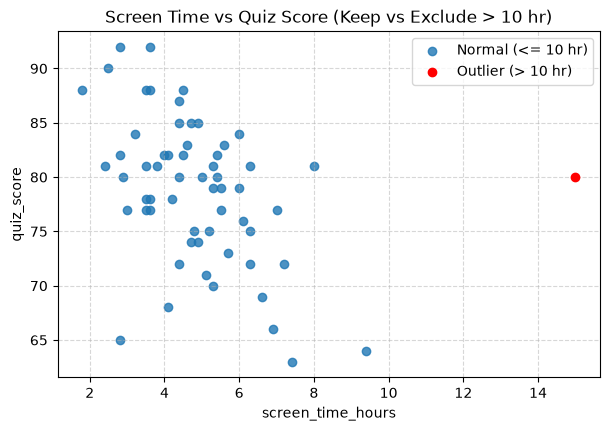

驗證通過：原始 df 完整保留，篩選條件與筆數一致。


In [7]:
# 學生小任務 MB：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。
import matplotlib.pyplot as plt

# 1. 科系分組筆數與平均成績（不修改原始 df）
dept_summary = df.groupby("department")["quiz_score"].agg(
    筆數="count",
    平均成績=lambda s: round(s.mean(), 2)
)
print("=== 1. 各科系分組筆數與平均成績 ===")
print(dept_summary)
print()

# 2. 睡眠時間與成績的有效配對數與相關分析
valid_sleep = df.dropna(subset=["sleep_hours", "quiz_score"])
sleep_corr = valid_sleep["sleep_hours"].corr(valid_sleep["quiz_score"])
print("=== 2. 睡眠時間與成績（有效配對） ===")
print(f"有效配對數：{len(valid_sleep)} 筆")
print(f"皮爾森相關係數：{sleep_corr:.3f}")
print()

# 3. 比較「保留」vs「排除」screen_time_hours > 10 小時的結果
df_keep = df.dropna(subset=["screen_time_hours", "quiz_score"])
df_clean = df_keep[df_keep["screen_time_hours"] <= 10]

corr_keep = df_keep["screen_time_hours"].corr(df_keep["quiz_score"])
corr_clean = df_clean["screen_time_hours"].corr(df_clean["quiz_score"])

print("=== 3. 螢幕時間與成績（保留 vs 排除 > 10 小時極端紀錄） ===")
print(f"保留全部（有效配對 {len(df_keep)} 筆）：相關係數 = {corr_keep:.3f}，平均螢幕時間 = {df_keep['screen_time_hours'].mean():.2f} 小時")
print(f"排除 > 10 小時（有效配對 {len(df_clean)} 筆）：相關係數 = {corr_clean:.3f}，平均螢幕時間 = {df_clean['screen_time_hours'].mean():.2f} 小時")

# 4. 繪製散佈圖（以不同顏色區分一般紀錄與 > 10 小時紀錄）
outliers = df_keep[df_keep["screen_time_hours"] > 10]

plt.figure(figsize=(7, 4.5))
plt.scatter(df_clean["screen_time_hours"], df_clean["quiz_score"], label="Normal (<= 10 hr)", alpha=0.8)
plt.scatter(outliers["screen_time_hours"], outliers["quiz_score"], color="red", label="Outlier (> 10 hr)", zorder=5)
plt.title("Screen Time vs Quiz Score (Keep vs Exclude > 10 hr)")
plt.xlabel("screen_time_hours")
plt.ylabel("quiz_score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 5. 可重跑驗證檢查（確保原始 df 未被修改，且條件篩選無誤）
assert len(df) == 60, "原始 df 筆數應維持 60 筆"
assert len(df_clean) + len(outliers) == len(df_keep), "篩選前後總筆數不符"
print("驗證通過：原始 df 完整保留，篩選條件與筆數一致。")

### ✍️ 小任務 MB｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：學習行為與測驗成績之關聯，使用本單元重建的60筆學生模擬資料表`df`，分析欄位包含`department`、`sleep_hours`、`screen_time_hours`與 `quiz_score`。
- 實際輸出與至少一項依據數字的觀察：
  1. **各科系分組表現**：`df` 總計60筆資料，其中企業管理 21筆（平均80.67分）、資訊管理 15筆（平均79.73分）、金融管理 24筆（平均76.58分）。
  2. **有效配對相關分析**：`sleep_hours` 扣除2筆缺失值後有效配對為58筆，與`quiz_score`的皮爾森相關係數為`-0.015`，幾乎無線性相關。
  3. **螢幕時間極端值敏感度比較**：保留全部60筆有效配對時，`screen_time_hours`平均為4.95小時，與`quiz_score`相關係數為`-0.364`；排除大於10小時的1筆極端紀錄後，剩餘59筆有效配對的平均螢幕時間降為4.78小時，相關係數則變為`-0.509`。
- 圖表或模型結果的解讀（依任務要求）：從`screen_time_hours`與`quiz_score`散佈圖可觀察到，59筆一般紀錄（藍色點）的螢幕時間集中在10小時以內，且隨著螢幕時間增加，成績呈現明顯向右下傾斜的負相關趨勢，而右側獨立的紅色點明顯偏離主群體，使整體相關係數從`-0.509`減弱為`-0.364`。
- 資料品質、模擬資料或評估限制：本資料集僅60筆，且為固定亂數種子搭配公式生成的模擬資料，其中`sleep_hours`有2筆缺失值，`screen_time_hours` 的15小時極端值亦是在成績計算後才人為寫入。分析結果僅反映資料處理方式對統計指標的影響，不能推論真實世界中減少螢幕時間就會導致成績提升。
- 驗證方法與結果：在程式中加入`assert`斷言檢查，驗證原始`df`筆數維持60筆未被修改，且篩選條件`<= 10`與`>10`筆數相加等於有效總筆數60筆；執行後順利印出驗證通過：原始 df 完整保留，篩選條件與筆數一致。
- AI 工具、實際提示詞、人工修改與遇到的問題：Gemini。我是 Python 初學者，請協助我完成以下資料分析小任務：請協助我規劃資料分析報告：包含分組人數和平均、有效配對、圖表與 15 小時紀錄的兩種處理比較。保留df、不要憑空填寫結果，並指出因果推論限制。請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。」遇到的問題與人工修改：初次繪製散佈圖時因圖例`label`使用中文，導致`matplotlib`跳出缺字警告且圖例顯示為方框亂碼；將圖表標題、座標軸與圖例全面改為英文`Normal (<= 10 hr)` 與 `Outlier (> 10 hr)`後順利消除警告，並於報告中全數填入程式實際輸出的數值。
- 重新執行是否成功及環境或檔案需求：執行全部執行可從頭順利重跑並通過所有驗證，不需額外讀取外部本機檔案；執行環境為本機Jupyter Notebook。
